# 2. Cleaning: gaps, false zeros, and outliers (and a leak)

**Life Expectancy Predictor · notebook 2 of 7**

Notebook 1 found three kinds of problem in the raw data: blank values, zeros that really mean "not reported", and extreme values. This notebook shows how each one is handled, and then explains a subtle mistake in the original version of this project (a *data leak*) and how it was fixed.

Every step here uses the project's own cleaning code (`data_prep.py`), so what you see is exactly what the model is trained on.

## Step 1: Turn hidden gaps into real gaps

**What we are looking for.** The zeros and impossible values from notebook 1 should become blanks, so that they get filled in sensibly instead of being believed.

In [1]:
# Setup: find the project folder and load the project's own code and settings.
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "config").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from config_loader import load_config

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config = load_config(str(ROOT / "config" / "who_life_expectancy.yaml"), base_dir=str(ROOT))

def results(name):
    """Load one of the saved results files in model/."""
    return json.loads((ROOT / "model" / f"{name}.json").read_text(encoding="utf-8"))

print("Project folder:", ROOT.name)
from data_prep import _clean_column_names, _fix_implicit_nulls, load_and_clean, get_unclipped_df

raw = _clean_column_names(pd.read_csv(config.source_csv), config)
fixed = _fix_implicit_nulls(raw, config)

cols = list(config.zero_as_null) + list(config.range_as_null)
before = raw[cols].isna().sum()
after = fixed[cols].isna().sum()
pd.DataFrame({"Blank before": before, "Blank after": after, "Newly blank": after - before})

Project folder: nb


,Blank before,Blank after,Newly blank
Infant_Deaths,0,838,838
Under-Five_Deaths,0,775,775
Pct_Expenditure,0,606,606
BMI,32,1446,1414


**How to read it.** For each column, how many values were blank in the file, and how many are blank after the fix. The difference is the number of disguised gaps we exposed.

**What it means.** Nothing has been invented yet; we have only stopped believing values that cannot be true. Health expenditure gained 606 blanks and BMI 1,414 (on top of 32 already blank). The rules for this live in the project's settings file (`config/who_life_expectancy.yaml`), so they are written down, not buried in code.

**What's next and why.** Blanks cannot go into a model, so the next step fills them in.

## Step 2: Fill the gaps from each country's own history

**What we are looking for.** A sensible value for each blank. The best guess for a country's missing 2008 figure is usually its own 2007 and 2009 figures, not the world average.

In [2]:
clean = load_and_clean(config)

# Show the idea on one country and one column with real gaps.
country, col = "Algeria", "Hepatitis_B"
example = pd.DataFrame({
    "Year": raw.loc[raw.Country == country, "Year"].values,
    "In the file": raw.loc[raw.Country == country, col].values,
    "After filling": clean.loc[clean.Country == country, col].values,
}).set_index("Year").sort_index().T
display(example)

# And the overall picture: how many values were filled, by method.
feature_cols = [c for c in clean.columns if c not in set(config.id_columns) | {config.target_column}]
gaps = fixed[feature_cols].isna()
print(f"Values filled in total: {int(gaps.values.sum()):,} of {gaps.size:,} "
      f"({gaps.values.mean():.1%} of all input values).")
print("Blanks remaining after filling:", int(clean[feature_cols].isna().sum().sum()))

Year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015
In the file,NaN,NaN,NaN,NaN,81.0,83.0,8.0,9.0,91.0,94.0,95.0,95.0,95.0,95.0,95.0,95.0
After filling,81.0,81.0,81.0,81.0,81.0,83.0,8.0,9.0,91.0,94.0,95.0,95.0,95.0,95.0,95.0,95.0


Values filled in total: 6,146 of 52,704 (11.7% of all input values).
Blanks remaining after filling: 0


**How to read it.** The example shows Algeria's hepatitis B immunization rate: blank for 2000-2003 in the file, and filled with 81 (its first known value, from 2004) afterwards. The two lines below give the totals.

**What it means.** The filling works in three tiers, used in order:

1. **Use the country's own neighbouring years.** A gap between two known years gets a value on the straight line between them; a gap at the start or end of the run gets the nearest known value carried across, as with Algeria. (In this dataset every gap turned out to be at the start or end of a country's run: health spending in 2015, for instance.)
2. **If a country has some values but tier 1 cannot reach the gap**, use that country's own typical (median) value.
3. **If a country has no values at all** (Korea's income index, for example), use the typical value across all countries.

Tier 3 is the weakest guess, and it is used only when nothing better exists. About 12% of all input values were filled one way or another; after this step there are no blanks left.

**What's next and why.** Gaps are fixed; now extreme values.

## Step 3: Tame extreme values (outlier clipping)

**What we are looking for.** A few values are far outside the normal range: reported measles cases in the hundreds of thousands, for instance. A model can be pulled around by them. The standard remedy is *winsorizing*: pulling the most extreme few percent of values in to the edge of the normal range.

,Column,Lowest % pulled up,Highest % pulled down
0,Adult_Mortality,0,3
1,Alcohol,0,1
2,Pct_Expenditure,0,13
3,Hepatitis_B,11,0
4,Measles,0,19
5,Under-Five_Deaths,0,11
6,Polio,10,0
7,Ttl_Expend,0,2
8,Diphtheria,10,0
9,HIV_AIDS,0,16


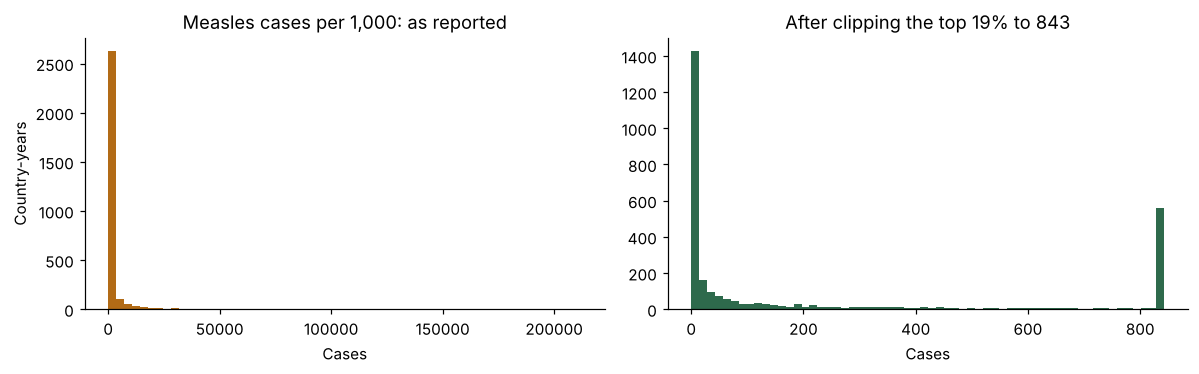

In [3]:
limits = pd.DataFrame(
    [(c, lo, hi) for c, (lo, hi) in config.winsorize_limits.items() if c in config.predictor_columns],
    columns=["Column", "Lowest % pulled up", "Highest % pulled down"],
)
limits["Lowest % pulled up"] = (limits["Lowest % pulled up"] * 100).round(0).astype(int)
limits["Highest % pulled down"] = (limits["Highest % pulled down"] * 100).round(0).astype(int)
limits = limits[(limits.iloc[:, 1] > 0) | (limits.iloc[:, 2] > 0)].reset_index(drop=True)
display(limits)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
s = clean["Measles"]
ax[0].hist(s, bins=60, color="#B26B16"); ax[0].set(title="Measles cases per 1,000: as reported", xlabel="Cases", ylabel="Country-years")
cut = np.sort(s.values)[len(s) - 1 - int(0.19 * len(s))]
ax[1].hist(np.clip(s, None, cut), bins=60, color="#2E6A4C"); ax[1].set(title=f"After clipping the top 19% to {cut:,.0f}", xlabel="Cases")
plt.tight_layout(); plt.show()

**How to read it.** The table lists, for each input, what share of the lowest and highest values are pulled in. The two charts show measles before and after: a few enormous values on the left stretch the whole scale; on the right those are capped and the shape of the typical data is visible.

**What it means.** Clipping does not delete rows. A country with 50,000 reported measles cases still counts as "very many cases", just not 100 times more than the next country. The percentages were chosen in the original project by looking at each column's distribution and are recorded in the settings file.

**What's next and why.** Clipping looks harmless, but *when* it is done matters. That is the leak.

## Step 4: The leak, and the fix

**What we are looking for.** A fair test of a model must keep the test data completely out of sight during training. The original project clipped the whole dataset *before* splitting it into training and test rows. The clip limits ("the top 16% of HIV values") were therefore partly set by looking at the test rows. The model never saw their answers, but the preparation step did, so the test was not perfectly clean.

The fix: clipping became part of the model itself. It learns its limits from the training rows only, and applies them to the test rows. Below, the limits learned from one training split are compared with limits learned from everything, to show the difference is real but small.

In [4]:
from data_prep import fold_winsorizer
from sklearn.model_selection import GroupKFold

df = get_unclipped_df(config)
X = df[config.predictor_columns].to_numpy()
train_idx, test_idx = next(GroupKFold(n_splits=5).split(X, groups=df["Country"]))

on_all = fold_winsorizer(config).fit(X)
on_train = fold_winsorizer(config).fit(X[train_idx])
cmp = pd.DataFrame({
    "Upper limit, learned from all rows (leaky)": on_all.upper_,
    "Upper limit, learned from training rows only": on_train.upper_,
}, index=config.predictor_columns)
cmp = cmp[np.isfinite(cmp.iloc[:, 0])].round(2)
display(cmp)

leak = results("leak_check")
print("Scores with the old, leaky clipping vs the new, leak-free clipping")
print(pd.DataFrame({
    "Old (clip everything first)": [leak["A_old"]["random_split_r2"], leak["A_old"]["group_cv_r2"], leak["A_old"]["group_oof_mae"]],
    "New (clip inside training only)": [leak["D_new"]["random_split_r2"], leak["D_new"]["group_cv_r2"], leak["D_new"]["group_oof_mae"]],
}, index=["R² on a random split", "R² on unseen countries", "Average miss on unseen countries (years)"]).to_string())
print(f"\nThe old version also clipped the target itself: {leak['target_rows_changed_by_old_clipping']} true life-expectancy values "
      f"below {leak['target_floor_old']} years were raised to {leak['target_floor_old']}. The lowest real value is {leak['target_min_true']}.")

,"Upper limit, learned from all rows (leaky)","Upper limit, learned from training rows only"
Adult_Mortality,453.00,441.00
HIV_AIDS,2.30,2.10
Under-Five_Deaths,83.00,87.00
Thinness_10-19_Years,14.60,14.40
Alcohol,13.49,13.94
Pct_Expenditure,1299.46,1212.67
Ttl_Expend,11.69,11.87
Schooling,19.00,18.60
Measles,843.00,830.00


Scores with the old, leaky clipping vs the new, leak-free clipping
                                          Old (clip everything first)  New (clip inside training only)
R² on a random split                                           0.9615                           0.9603
R² on unseen countries                                         0.9019                           0.9010
Average miss on unseen countries (years)                       2.1150                           2.1390

The old version also clipped the target itself: 28 true life-expectancy values below 45.6 years were raised to 45.6. The lowest real value is 36.3.


**How to read it.** The first table shows the cut-off above which values are clipped, for each input, under the two approaches. The second compares the project's headline scores before and after the fix (R² is explained in notebook 3; for now, closer to 1 is better, and "average miss" is in years of life expectancy).

**What it means.** The limits differ only slightly, and so do the scores: R² on unseen countries moved from 0.902 to 0.901 and the average miss from 2.12 to 2.14 years. The leak was real but tiny. It was still worth fixing, for two reasons:

- The published scores can now be defended as a clean test. "The test rows influenced nothing" is a simple claim; "they influenced only the clip limits a little" is not.
- The old version also clipped the *answer* (life expectancy) for 28 country-years, raising values below 45.6 years up to 45.6. A model trained on altered answers cannot learn how bad the worst cases really are. Clipping now never touches the target.

**What's next and why.** The data is clean and the preparation is leak-free. Notebook 3 trains the model and tests it in the two ways that give the two different headline numbers.

## Summary

| Problem | Fix | Where it lives |
| --- | --- | --- |
| Zeros meaning "not reported"; impossible BMI | Treated as blanks | `implicit_nulls` in the settings file |
| Blanks | Filled from the country's own years, then its median, then the global median | `data_prep.load_and_clean` |
| Extreme values | Clipped to the edge of the normal range, per column | `winsorize_limits` in the settings file |
| Clip limits saw the test data (leak) | Clipping moved inside the model; learned from training rows only | `data_prep.FoldWinsorizer` |
| The answer itself was clipped | Never clipped now | same |